# Gradient descent

[Linear regression](../algorithms/linear-models/linear_regression.ipynb) finds its best line with a formula: the least-squares error has an exact minimum that matrix algebra computes directly. Most models have no such formula. [Logistic regression](../algorithms/linear-models/logistic_regression.ipynb), neural networks, and many others are fitted by **gradient descent**: start from some parameters, find the direction in which the error falls fastest, take a small step that way, and repeat. It is built here by hand on linear regression, where the exact answer is known and every step can be checked against it.

## One parameter

The simulated salaries of [Linear regression](../algorithms/linear-models/linear_regression.ipynb), the same 30 employees, in thousands of euros, against years of experience. The model is a line, $\hat{y} = m x + b$, and its error the mean squared error:

$$J(m, b) = \frac{1}{n} \sum_{i=1}^{n} (y_i - m x_i - b)^2$$

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=30).round(1)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=30)
salaries = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})

x = salaries["YearsExperience"].to_numpy()
y = salaries["Salary"].to_numpy() / 1000

The exact answer, for reference:

In [ ]:
from sklearn.linear_model import LinearRegression

exact = LinearRegression().fit(x.reshape(-1, 1), y)
exact_slope, exact_intercept = exact.coef_[0], exact.intercept_
exact_slope, exact_intercept

(np.float64(2.5501297225918216), np.float64(22.785630426226156))

To see one step clearly, fix the intercept at its exact value and let only the slope $m$ change. The error is then a parabola in $m$, and its **derivative** at any point says which way is downhill and how steep it is:

$$\frac{\partial J}{\partial m} = -\frac{2}{n} \sum_{i=1}^{n} x_i \, (y_i - m x_i - b)$$

Gradient descent moves $m$ against the derivative, by a step proportional to it: $m \leftarrow m - \eta \, \partial J / \partial m$, where $\eta$ is the **learning rate**. Starting from $m = 0$:

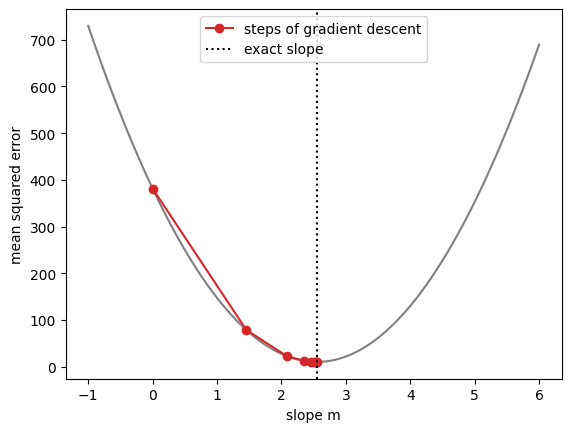

In [ ]:
import matplotlib.pyplot as plt


def error(slope, intercept, x_values=x):
    return np.mean((y - slope * x_values - intercept) ** 2)


slope, learning_rate, path = 0.0, 0.005, [0.0]
for _ in range(8):
    derivative = -2 * np.mean(x * (y - slope * x - exact_intercept))
    slope -= learning_rate * derivative
    path.append(slope)

slopes = np.linspace(-1, 6, 200)
plt.plot(slopes, [error(s, exact_intercept) for s in slopes], color="gray")
plt.plot(path, [error(s, exact_intercept) for s in path], "o-", color="tab:red", label="steps of gradient descent")
plt.axvline(exact_slope, color="black", linestyle=":", label="exact slope")
plt.xlabel("slope m")
plt.ylabel("mean squared error")
plt.legend()
plt.show()

The first step is long, because far from the minimum the parabola is steep; each step after it is shorter, because the derivative shrinks as the minimum gets closer, until the steps are imperceptible. Nothing tells gradient descent where the minimum is: it only ever looks at the slope where it stands. After eight steps it is next to the exact slope, about 2.55 (thousand euros per year of experience).

## Two parameters

With both parameters free, the error is a surface over the plane of $(m, b)$, and its **gradient**, the vector of its two derivatives, points uphill. Each step goes against it:

$$\frac{\partial J}{\partial m} = -\frac{2}{n} \sum_i x_i (y_i - \hat{y}_i) \qquad \frac{\partial J}{\partial b} = -\frac{2}{n} \sum_i (y_i - \hat{y}_i)$$

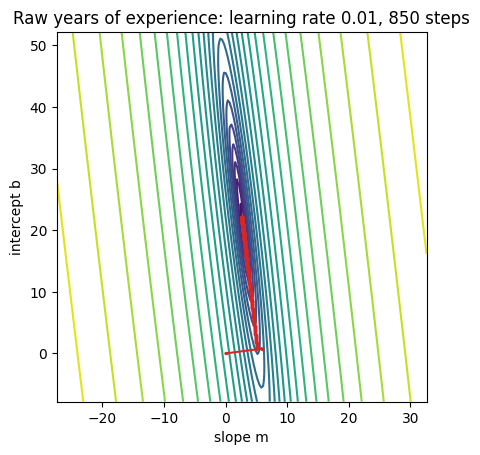

In [ ]:
def gradient_descent(x_values, learning_rate, steps):
    slope, intercept = 0.0, 0.0
    path = [(slope, intercept)]
    for _ in range(steps):
        residuals = y - slope * x_values - intercept
        slope += learning_rate * 2 * np.mean(x_values * residuals)
        intercept += learning_rate * 2 * np.mean(residuals)
        path.append((slope, intercept))
    return np.array(path)


def plot_path(x_values, path, title, half_width):
    center_slope, center_intercept = path[-1]
    slope_grid, intercept_grid = np.meshgrid(
        np.linspace(center_slope - half_width, center_slope + half_width, 200),
        np.linspace(center_intercept - half_width, center_intercept + half_width, 200))
    errors = np.array([[error(s, i, x_values) for s, i in zip(row_s, row_i)]
                       for row_s, row_i in zip(slope_grid, intercept_grid)])
    plt.contour(slope_grid, intercept_grid, np.log(errors), levels=25, cmap="viridis")
    plt.plot(path[:, 0], path[:, 1], ".-", color="tab:red", markersize=3)
    plt.gca().set_aspect("equal")
    plt.xlabel("slope m")
    plt.ylabel("intercept b")
    plt.title(title)
    plt.show()


raw_path = gradient_descent(x, learning_rate=0.01, steps=850)
plot_path(x, raw_path, "Raw years of experience: learning rate 0.01, 850 steps", half_width=30)

Both axes have the same scale, so the shape is honest: the error is a long, narrow valley, very steep across and almost flat along. The first step crosses it at once, raising the slope to about 6; the rest crawl along the floor of the valley towards the minimum, near a slope of 2.6 and an intercept of 23, and it takes over 800 of them to get there.

## Why scaling matters here

The slope and the intercept affect the error in very different amounts: the slope multiplies years of experience, which average almost 7, and the intercept multiplies nothing. The error is far steeper along one direction than the other, a long narrow valley, and a single learning rate must be small enough for the steep direction, so it crawls along the flat one. Standardising the feature, so that it has mean 0 and standard deviation 1 ([California housing, step by step](../basic-workflows/california_by_hand.ipynb)), makes the two directions equally steep:

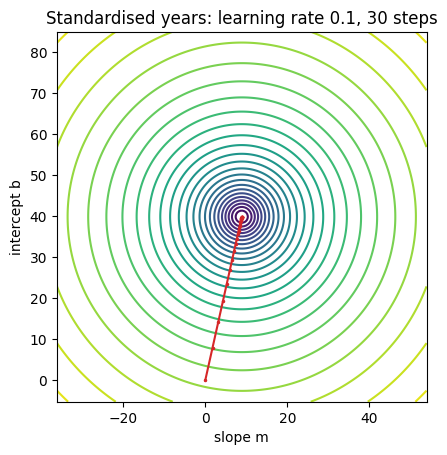

In [ ]:
x_scaled = (x - x.mean()) / x.std()
scaled_path = gradient_descent(x_scaled, learning_rate=0.1, steps=30)
plot_path(x_scaled, scaled_path, "Standardised years: learning rate 0.1, 30 steps", half_width=45)

In [ ]:
minimum = error(exact_slope, exact_intercept)


def steps_to_reach(x_values, learning_rate, tolerance=0.01, max_steps=5000):
    path = gradient_descent(x_values, learning_rate, max_steps)
    errors = np.array([error(s, i, x_values) for s, i in path])
    close = np.flatnonzero(errors <= (1 + tolerance) * minimum)
    return int(close[0]) if len(close) else None


{"raw years, learning rate 0.01": steps_to_reach(x, 0.01), "standardised years, learning rate 0.1": steps_to_reach(x_scaled, 0.1)}

{'raw years, learning rate 0.01': 827,
 'standardised years, learning rate 0.1': 22}

827 steps with the raw feature, 22 with the standardised one. The circles show why: with both directions equally steep, the gradient points straight at the minimum, and every step goes there. And a learning rate of 0.1 wouldn't even work on the raw feature: 0.02 is already too large for its steep direction, and the steps grow without end. This is why scaling matters for everything trained by gradient descent, from logistic regression to neural networks, and not for the exact formula of linear regression.

The line found on standardised years is the same line, in other units: converting its slope and intercept back to years recovers the exact answer:

In [ ]:
scaled_slope, scaled_intercept = gradient_descent(x_scaled, learning_rate=0.1, steps=200)[-1]
slope_in_years = scaled_slope / x.std()
intercept_in_years = scaled_intercept - slope_in_years * x.mean()
slope_in_years - exact_slope, intercept_in_years - exact_intercept

(np.float64(-8.881784197001252e-16), np.float64(-7.105427357601002e-15))

## The learning rate

The learning rate is the setting that decides whether gradient descent works at all. The error after each step, for four learning rates, on the standardised years:

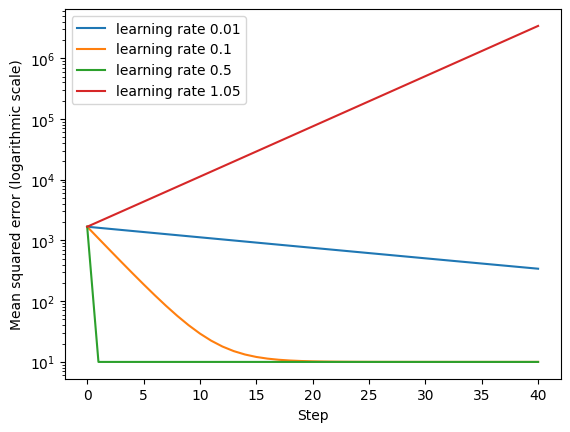

In [ ]:
for learning_rate in (0.01, 0.1, 0.5, 1.05):
    path = gradient_descent(x_scaled, learning_rate, steps=40)
    plt.plot([error(s, i, x_scaled) for s, i in path], label=f"learning rate {learning_rate}")
plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("Mean squared error (logarithmic scale)")
plt.legend()
plt.show()

With 0.01, the error falls steadily but slowly, and after 40 steps it is still far from the minimum. With 0.1 it reaches the minimum in about 20 steps. With 0.5 it gets there in one, and not by chance: with a standardised feature the error curves the same in every direction (its second derivative is 2), so a step of half the gradient lands exactly on the minimum. With 1.05 every step overshoots the minimum by more than the one before, and the error grows without limit. Between too slow and divergent lies a range of good values, and finding it is the first task when training anything by gradient descent.

## Where gradient descent is used

For linear regression it is a demonstration: the formula is exact and fast. Its place is everywhere else:

- **Logistic regression** has no formula for its best weights; scikit-learn's default solver is a refined descent method ([Logistic regression](../algorithms/linear-models/logistic_regression.ipynb#logistic-regression-with-a-single-independent-variable)).
- **Gradient boosting** takes gradient steps not on parameters but on the predictions themselves ([Gradient boosting](../algorithms/tree-based/gradient_boosting.ipynb#why-gradient-deep-dive)).
- **Neural networks** have millions or billions of parameters, and are trained by mini-batch gradient descent (a few rows per step: the last section); *backpropagation* is the method that computes their gradients efficiently, and libraries such as PyTorch compute them automatically.

The error of a linear or a logistic regression is **convex**: a single valley, so gradient descent, with a suitable learning rate, always reaches the same minimum (for logistic regression, thanks to its default penalty: without one, two classes that a line separates perfectly have no minimum at all). The error of a neural network is not: it has many valleys, and where descent ends depends on where it starts. That, and the tricks to deal with it, belong to neural networks.

## Many rows: batch, mini-batch and stochastic steps *(deep dive)*

Every step above used every row to compute the gradient: **batch** gradient descent. What follows matters most for neural networks, which are always trained on many rows this way; the classical models of this topic either have an exact formula or a library solver that takes care of it. With millions of rows, each step becomes expensive, and two cheaper variants are used instead. **Stochastic** gradient descent computes each step from a single random row; **mini-batch** gradient descent, from a small random group of rows, typically 32 to 512. Each step is a noisy estimate of the true gradient, but there are many more steps for the same amount of computation.

On the 16,512 training districts of California housing, with the eight features standardised, each variant goes through all the rows five times (five *epochs*), and the error on the training rows is measured after each:

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing(as_frame=True).frame
X_housing = housing.drop(columns="MedHouseVal").to_numpy()
y_housing = housing["MedHouseVal"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X_housing, y_housing, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)


def train_by_batches(batch_size, learning_rate, epochs=5, seed=0):
    rng = np.random.default_rng(seed)
    weights, intercept, errors = np.zeros(X_train_scaled.shape[1]), 0.0, []
    for _ in range(epochs):
        order = rng.permutation(len(X_train_scaled))
        for start in range(0, len(order), batch_size):
            rows = order[start:start + batch_size]
            residuals = y_train[rows] - (X_train_scaled[rows] @ weights + intercept)
            weights += learning_rate * 2 * X_train_scaled[rows].T @ residuals / len(rows)
            intercept += learning_rate * 2 * residuals.mean()
        errors.append(mean_squared_error(y_train, X_train_scaled @ weights + intercept))
    return errors


exact_error = mean_squared_error(y_train, LinearRegression().fit(X_train_scaled, y_train).predict(X_train_scaled))
pd.DataFrame({
    "batch (all rows), learning rate 0.3": train_by_batches(len(X_train_scaled), 0.3),
    "mini-batches of 32, learning rate 0.003": train_by_batches(32, 0.003),
    "one row at a time, learning rate 0.0001": train_by_batches(1, 0.0001),
}, index=pd.RangeIndex(1, 6, name="epoch")).div(exact_error).round(3)

,"batch (all rows), learning rate 0.3","mini-batches of 32, learning rate 0.003","one row at a time, learning rate 0.0001"
epoch,,,
1,2.780,1.192,1.180
2,1.478,1.105,1.099
3,1.249,1.064,1.059
4,1.194,1.040,1.036
5,1.171,1.036,1.034


The numbers are the training error divided by the exact minimum, so 1.000 would be the exact answer. After one pass through the data, the batch version has taken a single step and is at 2.8 times the minimum; the mini-batch and one-row versions have taken 516 and 16,512 small steps, and are within 20% of it. After five passes they are within 4%, while the batch version, five steps in, is still 17% above. This is why large models are trained with mini-batches: far more progress per pass over the data, at the cost of noisier steps. The noise also keeps them from settling exactly on the minimum, which a learning rate that shrinks over time fixes.

The one-row version needs a much smaller learning rate: with 0.001 it diverges on these data. One California district has a feature more than 100 standard deviations from the mean (its average occupancy), and three more beyond 50: one such row alone, in one step, throws the parameters far off; in a mini-batch it is averaged with 31 ordinary rows.

scikit-learn implements stochastic gradient descent for linear models in `SGDRegressor` and `SGDClassifier`, with refinements: a learning rate that shrinks over time, a penalty, and a stopping rule. As always with gradient descent, the features are scaled first:

In [ ]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline

sgd = make_pipeline(StandardScaler(), SGDRegressor(random_state=42)).fit(X_train, y_train)
least_squares = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
{
    "SGDRegressor, test MAE ($)": 100_000 * mean_absolute_error(y_test, sgd.predict(X_test)),
    "exact least squares, test MAE ($)": 100_000 * mean_absolute_error(y_test, least_squares.predict(X_test)),
    "epochs SGDRegressor needed": sgd[-1].n_iter_,
}

{'SGDRegressor, test MAE ($)': 52988.27241446434,
 'exact least squares, test MAE ($)': 53320.01304956566,
 'epochs SGDRegressor needed': 6}

`SGDRegressor` reaches the test error of the exact formula, within a few hundred dollars, after 6 epochs. On 16,000 rows the formula is quicker; with data that doesn't fit in memory, data that keeps arriving, or a very large number of features, stochastic gradient descent is the practical way.